In [28]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# 1. Load Data (Agar housing.csv folder me nahi hai to download karega)
if not os.path.exists("housing.csv"):
    url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
    urllib.request.urlretrieve(url, "housing.csv")
    print("housing.csv downloaded successfully!")

housing = pd.read_csv("housing.csv")
print("Dataset Shape:", housing.shape)
housing.head()

Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
None


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


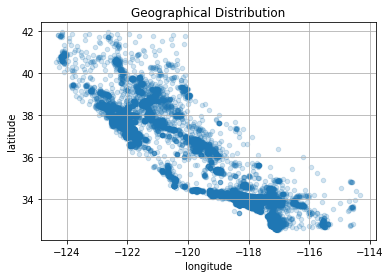


Correlation with Median House Value:
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


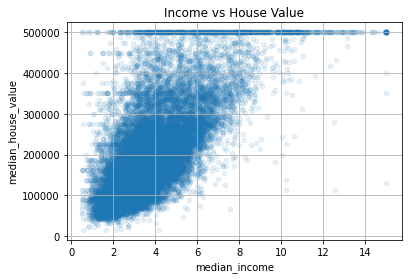

In [20]:
# Data ki basic information aur statistics dekhne ke liye[cite: 11]
print(housing.info())
display(housing.describe())

# Geographical Scatter Plot[cite: 16]
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2, title="Geographical Distribution")
plt.show()

# Correlation check karna (Numeric columns ke liye)[cite: 16]
# Line 10 ko isse replace karein:
corr_matrix = housing.select_dtypes(include=[np.number]).corr()
print("\nCorrelation with Median House Value:")
print(corr_matrix["median_house_value"].sort_values(ascending=False))

# Income vs House Value Scatter Plot[cite: 17]
housing.plot(kind="scatter", x="median_income", y="median_house_value", alpha=0.1, grid=True, title="Income vs House Value")
plt.show()

In [22]:
# Income ke basis par strata (categories) banana[cite: 14]
housing["income_cat"] = pd.cut(
    housing["median_income"],
    bins=[0.0, 1.5, 3.0, 4.5, 6.0, np.inf],
    labels=[1, 2, 3, 4, 5]
)

# Stratified Shuffle Split (80% Train, 20% Test)[cite: 15]
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(housing, housing["income_cat"]):
    strat_train_set = housing.loc[train_index].drop("income_cat", axis=1)
    strat_test_set = housing.loc[test_index].drop("income_cat", axis=1)

# Predictors (X) aur Labels (y) ko alag karna[cite: 32]
housing_train = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

# Numerical aur Categorical columns define karna[cite: 32]
num_attribs = housing_train.drop("ocean_proximity", axis=1).columns.tolist()
cat_attribs = ["ocean_proximity"]

# Numerical Pipeline (Missing values -> Median, Scaling -> StandardScaler)[cite: 32]
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical Pipeline (One-Hot Encoding)[cite: 32]
cat_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Full Pipeline[cite: 32]
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs),
])

# Data ko transform karna[cite: 32]
housing_prepared = full_pipeline.fit_transform(housing_train)
print("Prepared Data Shape:", housing_prepared.shape)

Prepared Data Shape: (16512, 13)


In [24]:


# 1. Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(housing_prepared, housing_labels)
lin_preds = lin_reg.predict(housing_prepared)
lin_rmse = np.sqrt(mean_squared_error(housing_labels, lin_preds))
print("Linear Regression Training RMSE:", lin_rmse)

# 2. Decision Tree Regressor
tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(housing_prepared, housing_labels)
tree_preds = tree_reg.predict(housing_prepared)
tree_rmse = np.sqrt(mean_squared_error(housing_labels, tree_preds))
print("Decision Tree Training RMSE:", tree_rmse)

# 3. Random Forest Regressor
forest_reg = RandomForestRegressor(random_state=42)
forest_reg.fit(housing_prepared, housing_labels)
forest_preds = forest_reg.predict(housing_prepared)
forest_rmse = np.sqrt(mean_squared_error(housing_labels, forest_preds))
print("Random Forest Training RMSE:", forest_rmse)

# Cross-Validation on Decision Tree & Random Forest
print("\nRunning 10-Fold Cross Validation (Wait a few seconds)...")
tree_rmses = -cross_val_score(tree_reg, housing_prepared, housing_labels, scoring="neg_root_mean_squared_error", cv=10)
print("Decision Tree CV Mean RMSE:", tree_rmses.mean())

forest_rmses = -cross_val_score(forest_reg, housing_prepared, housing_labels, scoring="neg_root_mean_squared_error", cv=10)
print("Random Forest CV Mean RMSE:", forest_rmses.mean())

Linear Regression Training RMSE: 69055.96999041548
Decision Tree Training RMSE: 0.0
Random Forest Training RMSE: 18381.60959473712

Running 10-Fold Cross Validation (Wait a few seconds)...
Decision Tree CV Mean RMSE: 69402.78675133755
Random Forest CV Mean RMSE: 49609.38012992901


In [29]:
MODEL_FILE = "model.pkl"
PIPELINE_FILE = "pipeline.pkl"

# Test set se ek sample 'input.csv' banate hain testing ke liye
sample_input = strat_test_set.drop("median_house_value", axis=1).head(10)
sample_input.to_csv("input.csv", index=False)

# Model aur Pipeline save karna
joblib.dump(forest_reg, MODEL_FILE)
joblib.dump(full_pipeline, PIPELINE_FILE)
print("Model and Pipeline saved successfully!")

# Inference Phase (Saved model load karke predict karna)[cite: 39]
if os.path.exists(MODEL_FILE) and os.path.exists(PIPELINE_FILE):
    loaded_model = joblib.load(MODEL_FILE)
    loaded_pipeline = joblib.load(PIPELINE_FILE)
    
    input_data = pd.read_csv("input.csv")
    transformed_input = loaded_pipeline.transform(input_data)
    predictions = loaded_model.predict(transformed_input)
    
    input_data["predicted_house_value"] = predictions
    input_data.to_csv("output.csv", index=False)
    print("Inference complete! Results saved to 'output.csv'.")
    display(input_data[["ocean_proximity", "median_income", "predicted_house_value"]])

Model and Pipeline saved successfully!
Inference complete! Results saved to 'output.csv'.


,ocean_proximity,median_income,predicted_house_value
0,<1H OCEAN,8.2816,480198.57
1,<1H OCEAN,4.6111,224345.00
2,<1H OCEAN,3.0119,202069.00
3,INLAND,4.1518,222457.00
4,INLAND,4.0375,143577.00
5,INLAND,3.4331,134359.00
6,INLAND,1.0962,53909.00
7,NEAR OCEAN,7.0001,429270.23
8,INLAND,3.3534,104403.00
9,INLAND,3.0139,75982.00
